# Figures 2.1–2.3: AR minimum-width experiments

Run this notebook from top to bottom to reproduce the AR(1), AR(2), and AR(3) plots used as Figures 2.1–2.3. The fixed seeds, replications, and optimization settings are retained; order selection uses the shared-point affine-plus-constant LAD configuration. Each figure is saved as PDF and PNG to `Abschlussarbeit_2021/LaTeX/images/`. Set `AR_THESIS_FIGURES_DIR` before starting the notebook to write to another directory.

In [6]:
import os                                                                                           ### INFRASTRUCTURE
import sys                                                                                          ### INFRASTRUCTURE
from pathlib import Path                                                                            ### INFRASTRUCTURE

import matplotlib.pyplot as plt                                                                     ### PLOTTING
import numpy as np
import pandas as pd                                                                                 ### REPORTING
AR_CODE_DIR = next(                                                                                 ### INFRASTRUCTURE
    (                                                                                               ### INFRASTRUCTURE
        candidate.resolve()                                                                         ### INFRASTRUCTURE
        for root in (Path.cwd(), *Path.cwd().parents)                                               ### INFRASTRUCTURE
        for candidate in (root / "Code" / "Code_AR_processes", root)                                ### INFRASTRUCTURE
        if (candidate / "ar_tools/functions.py").is_file()                                          ### INFRASTRUCTURE
        and (candidate / "ar_tools/plotting_functions.py").is_file()                                ### INFRASTRUCTURE
    ),                                                                                              ### INFRASTRUCTURE
    None,                                                                                           ### INFRASTRUCTURE
)                                                                                                   ### INFRASTRUCTURE
if AR_CODE_DIR is None:                                                                             ### INFRASTRUCTURE
    raise FileNotFoundError("Could not locate Code/Code_AR_processes.")                             ### INFRASTRUCTURE
PROJECT_ROOT = AR_CODE_DIR.parents[1]                                                               ### INFRASTRUCTURE
if str(PROJECT_ROOT) not in sys.path:                                                               ### INFRASTRUCTURE
    sys.path.insert(0, str(PROJECT_ROOT))                                                           ### INFRASTRUCTURE

from Code.Code_AR_processes.ar_tools.descent import (
    batched_geometric_width_curves,
)
from Code.Code_AR_processes.ar_tools.L_method import l_method_selector
from Code.Code_AR_processes.ar_tools.functions import (
    ar_window_zonotope_generators,
    simulate_uniform_ar,
    sliding_window_point_cloud,
    theoretical_ar_width_in_direction,
)

FIGURE_OUTPUT_DIR = Path(os.environ.get(                                                            ### INFRASTRUCTURE
    "AR_THESIS_FIGURES_DIR",                                                                        ### INFRASTRUCTURE
    PROJECT_ROOT / "Abschlussarbeit_2021" / "LaTeX" / "images",                                     ### INFRASTRUCTURE
))                                                                                                  ### INFRASTRUCTURE
FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)                                                ### INFRASTRUCTURE

plt.style.use("seaborn-v0_8-whitegrid")                                                             ### PLOTTING
np.set_printoptions(precision=4, suppress=True)                                                     ### REPORTING

def coefficients_from_minimizing_direction(direction):
    """Recover phi_j = -u_j / u_0 as in Remark 3."""
    direction = np.asarray(direction, dtype=float)
    if direction.ndim != 1 or len(direction) < 2:
        raise ValueError("direction must contain u_0 and at least one lag coefficient")
    if np.isclose(direction[0], 0.0):
        raise ValueError("cannot recover coefficients when u_0 is zero")
    return -direction[1:] / direction[0]


def population_minimizing_direction(phi, k):
    """Choose a unit population minimum-width direction for an AR embedding."""
    phi = np.asarray(phi, dtype=float)
    if k == 1:
        return np.ones(1)
    if k >= len(phi) + 1:
        direction = np.r_[1.0, -phi, np.zeros(k - len(phi) - 1)]
        return direction / np.linalg.norm(direction)

    # In k=2 and k=3, minimum-width directions of the truncated
    # support zonotope occur among its facet normals.
    generators = ar_window_zonotope_generators(phi, k, history=200)
    if k == 2:
        candidates = np.column_stack((-generators[1], generators[0]))
    elif k == 3:
        left, right = np.triu_indices(generators.shape[1], 1)
        candidates = np.cross(generators[:, left].T, generators[:, right].T)
    else:
        raise ValueError("Pre-plateau directions are implemented for k <= 3")
    lengths = np.linalg.norm(candidates, axis=1)
    candidates = candidates[lengths > 1e-12] / lengths[lengths > 1e-12, None]
    widths = 2.0 * np.sum(np.abs(candidates @ generators), axis=1)
    return candidates[np.argmin(widths)]


## One complete AR(1) pipeline and its selected elbow

This reproducible example generates one stationary AR(1) process with innovations $\varepsilon_t\sim\mathrm{Unif}[-1,1]$, computes $\widehat m_k$ by three-start projected subgradient descent, and applies the unweighted shared-point affine-plus-constant LAD selector. The population result is shown only where it is used here: $m_k=m^*=2/\sqrt{1+\phi_1^2}$ for $k\ge p+1=2$. Two cross-evaluated curves separate sampling error from directional optimization error: $\widehat w_k(u_k^{\min})$ evaluates the empirical cloud in a population-minimizing direction, while $w_k(\widehat u_k)$ evaluates the population support width in the empirically minimized direction. For $k\ge2$, the chosen population minimizer is $u_k^{\min}=(1,-\phi_1,0,\ldots,0)/\sqrt{1+\phi_1^2}$; for $k=1$ it is the unique direction up to sign. For $k<p+1$, the population direction is obtained from a finite-history support-zonotope approximation. The selector's fitted lines are intentionally omitted so the four width curves remain visually prominent.

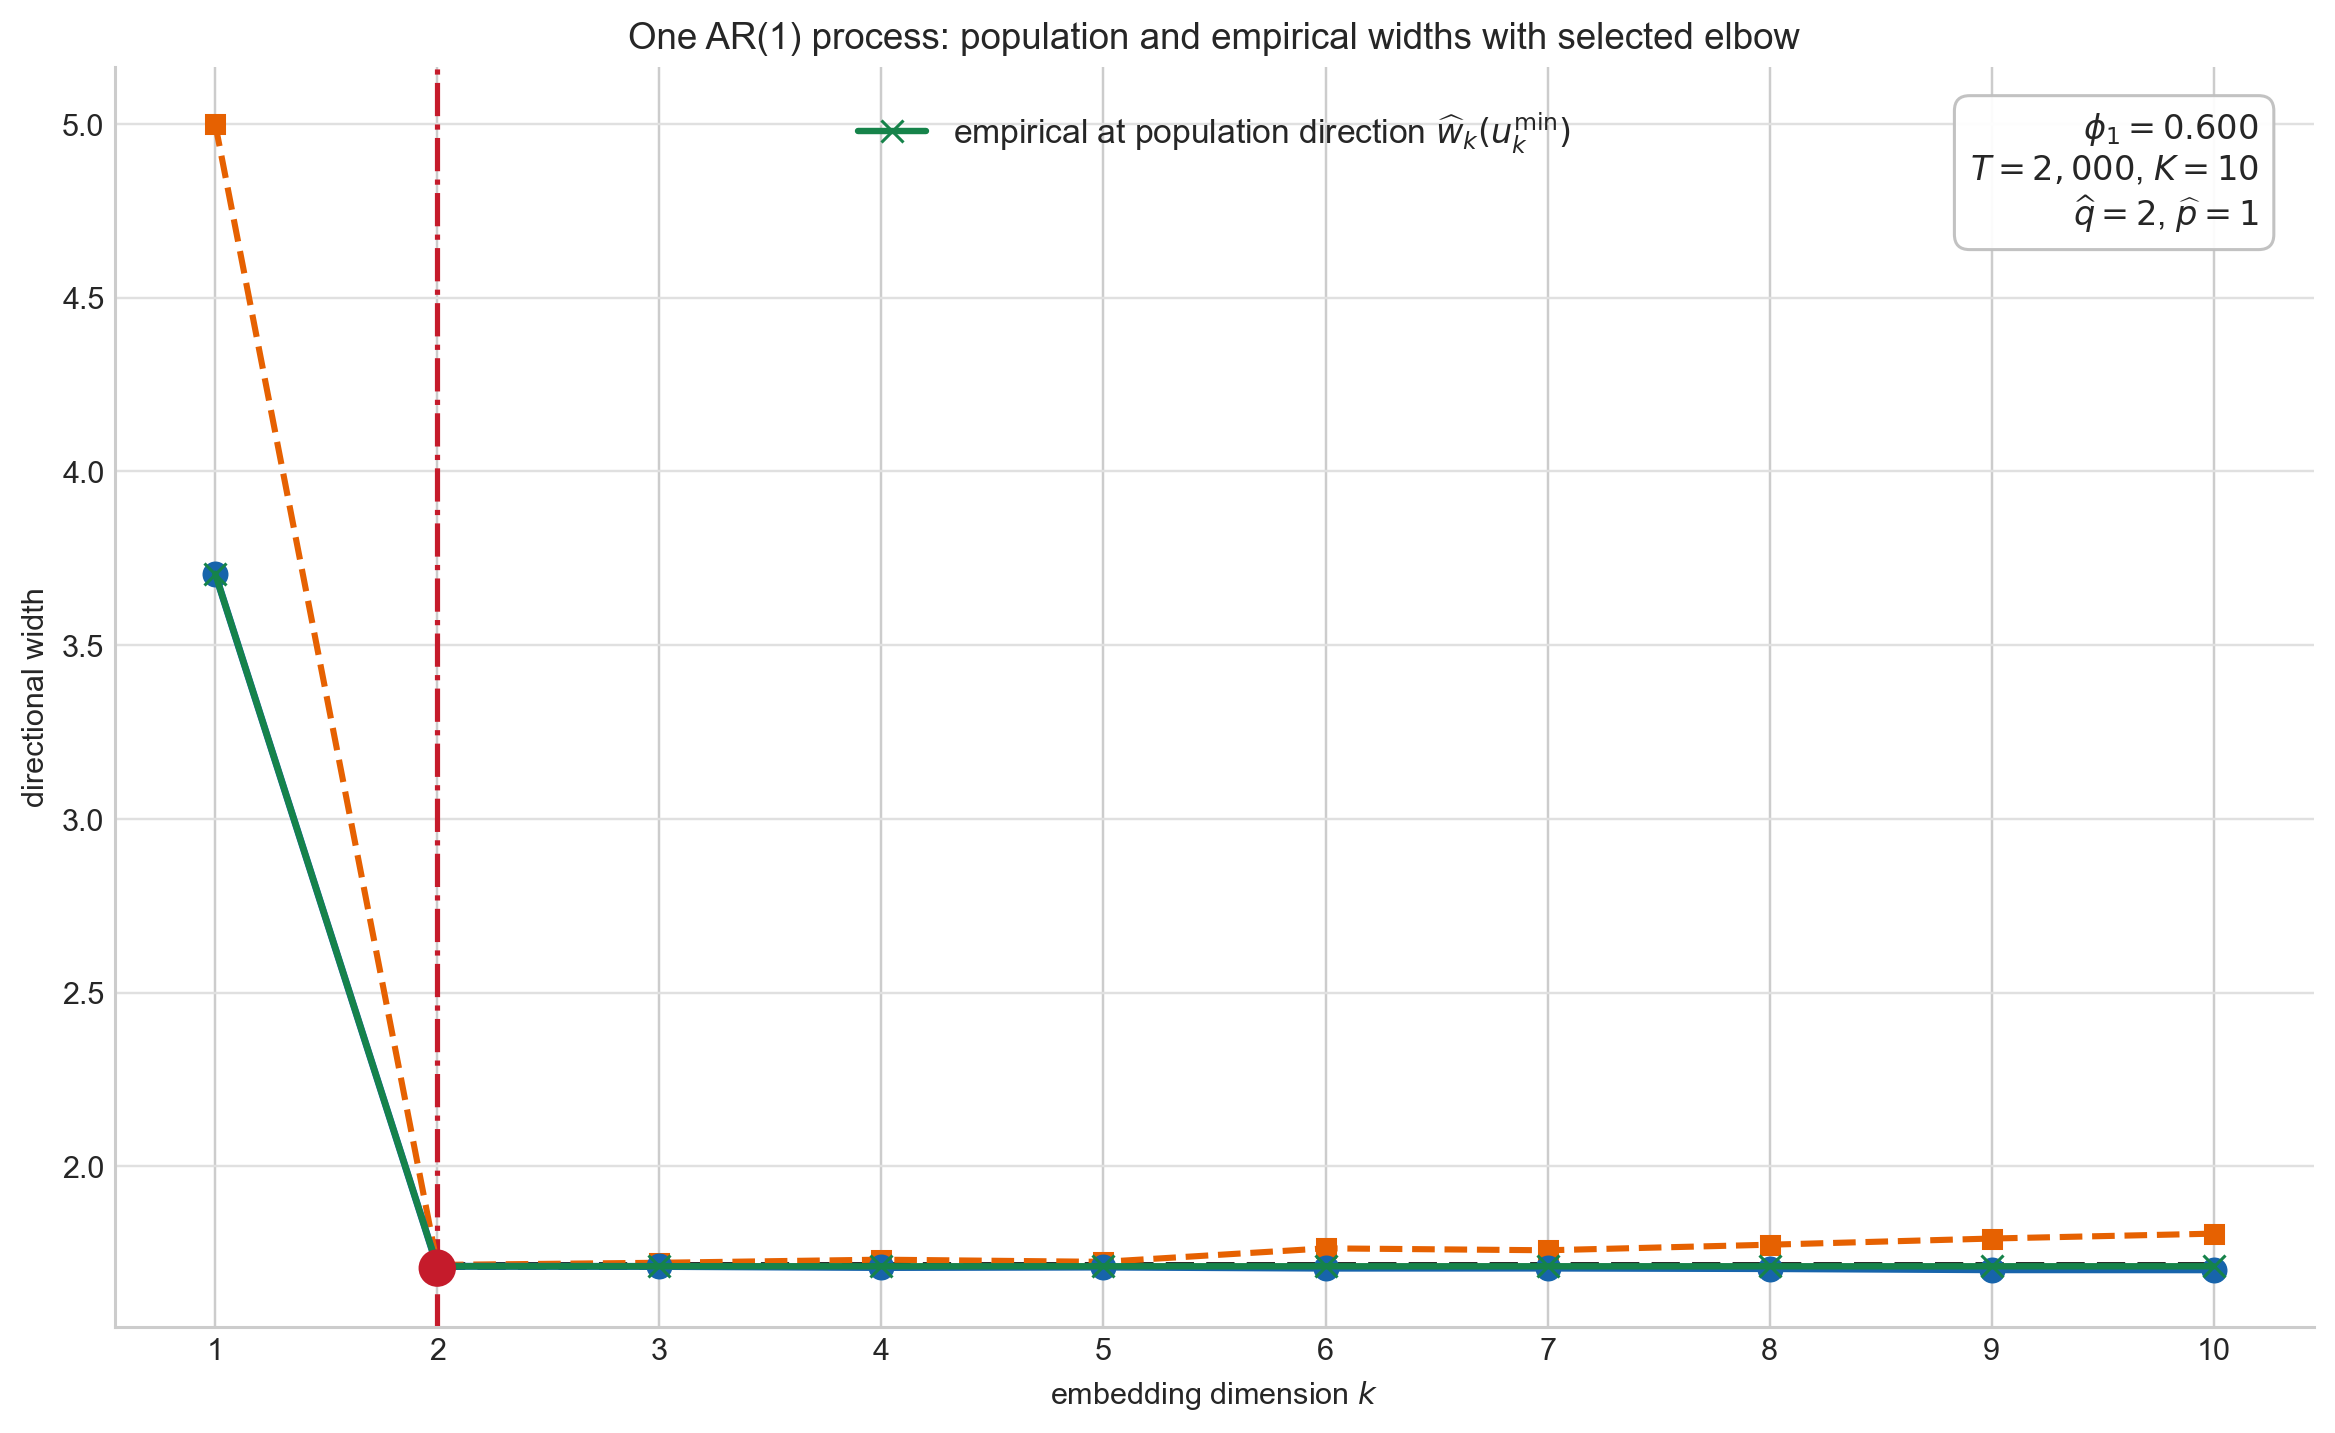

AR coefficient phi_1 = 0.600000
Population plateau m* = 1.714986
Selected q = 2; selected AR order p = 1; LAD score = 0.025905
Estimated coefficients from the empirical minimizing direction at k = 2:
  phi_1_hat = 0.599652


In [7]:
# Fixed coefficients and settings make the displayed process reproducible.
single_ar1_seed = 20260813
single_ar1_replication = 0
single_ar1_T = 2_000
single_ar1_burnin = 1_000
single_ar1_k_values = np.arange(1, 11)
single_ar1_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar1_seed, single_ar1_replication, 0
]))
single_ar1_phi = np.array([0.6])
single_ar1_series = simulate_uniform_ar(
    single_ar1_phi, single_ar1_T, single_ar1_burnin, 1.0,
    rng=single_ar1_generator,
)
_, single_ar1_widths, _, single_ar1_empirical_directions = (
    batched_geometric_width_curves(
    single_ar1_series,
    int(single_ar1_k_values.max()),
    seed=single_ar1_seed,
    replication=single_ar1_replication,
    starts=3,
    iterations=500,
    initial_step=0.2,
    geometric_decay=0.99,
    return_directions=True,
    )
)
single_ar1_selection = l_method_selector(
    single_ar1_widths, weighted=False, common_breakpoint=True,
    affine_affine=False, squared_loss=False,
)
single_ar1_q_hat = single_ar1_selection["plateau_onset"]
single_ar1_p_hat = single_ar1_selection["selected_order"]
single_ar1_estimated_phi = coefficients_from_minimizing_direction(
    single_ar1_empirical_directions[single_ar1_q_hat - 1]
)
single_ar1_population_width = 2.0 / np.sqrt(
    1.0 + single_ar1_phi[0] ** 2
)
single_ar1_population_directions = []
single_ar1_empirical_at_population_min = []
single_ar1_population_at_empirical_min = []
for k, empirical_direction in zip(
    single_ar1_k_values, single_ar1_empirical_directions
):
    population_direction = population_minimizing_direction(single_ar1_phi, int(k))
    cloud_k = sliding_window_point_cloud(single_ar1_series, int(k))
    population_direction_projections = cloud_k @ population_direction
    single_ar1_population_directions.append(population_direction)
    single_ar1_empirical_at_population_min.append(
        np.ptp(population_direction_projections)
    )
    single_ar1_population_at_empirical_min.append(
        theoretical_ar_width_in_direction(
            single_ar1_phi, empirical_direction, half_width=1.0
        )
    )
single_ar1_empirical_at_population_min = np.asarray(
    single_ar1_empirical_at_population_min
)
single_ar1_population_at_empirical_min = np.asarray(
    single_ar1_population_at_empirical_min
)

single_ar1_pipeline_results = pd.DataFrame({                                                        ### REPORTING
    "k": single_ar1_k_values,                                                                       ### REPORTING
    "empirical_width": single_ar1_widths,                                                           ### REPORTING
    "population_width": np.where(                                                                   ### REPORTING
        single_ar1_k_values >= 2, single_ar1_population_width, np.nan                               ### REPORTING
    ),                                                                                              ### REPORTING
    "empirical_at_population_min": (                                                                ### REPORTING
        single_ar1_empirical_at_population_min                                                      ### REPORTING
    ),                                                                                              ### REPORTING
    "population_at_empirical_min": (                                                                ### REPORTING
        single_ar1_population_at_empirical_min                                                      ### REPORTING
    ),                                                                                              ### REPORTING
    "selected_LAD_fit": single_ar1_selection["fitted_values"],                                      ### REPORTING
})                                                                                                  ### REPORTING

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)                              ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar1_k_values, single_ar1_widths, color="#1764ab",                                        ### PLOTTING
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,                                            ### PLOTTING
    label=r"empirical $\widehat m_k$",                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar1_k_values[1:],                                                                        ### PLOTTING
    np.full(len(single_ar1_k_values) - 1, single_ar1_population_width),                             ### PLOTTING
    color="black", linestyle="--", linewidth=2.5, zorder=2,                                         ### PLOTTING
    label=r"population $m_k=m^*$ for $k\geq2$",                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar1_k_values, single_ar1_population_at_empirical_min,                                    ### PLOTTING
    color="#e66101", marker="s", markersize=5.8,                                                    ### PLOTTING
    linestyle="--", linewidth=2.0, zorder=3,                                                        ### PLOTTING
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",                                 ### PLOTTING
)                                                                                                   ### PLOTTING

green_line, = axis.plot(                                                                            ### PLOTTING
    single_ar1_k_values, single_ar1_empirical_at_population_min,                                    ### PLOTTING
    color="#16834a", marker="x", markersize=7.5, linewidth=2.1, zorder=5,                           ### PLOTTING
    label=r"empirical at population direction $\widehat w_k(u_k^{\min})$",                          ### PLOTTING
)                                                                                                   ### PLOTTING
axis.legend(handles=[green_line], loc="upper center", bbox_to_anchor=(0.5, 0.99),                   ### PLOTTING
            frameon=False, fontsize=11)                                                             ### PLOTTING
axis.axvline(                                                                                       ### PLOTTING
    single_ar1_q_hat, color="#c51b2b", linestyle="-.",                                              ### PLOTTING
    linewidth=1.7, zorder=1,                                                                        ### PLOTTING
    label=rf"selected $\widehat q={single_ar1_q_hat}$ ($\widehat p={single_ar1_p_hat}$)",           ### PLOTTING
)                                                                                                   ### PLOTTING
axis.scatter(                                                                                       ### PLOTTING
    [single_ar1_q_hat], [single_ar1_selection["right_intercept"]],                                  ### PLOTTING
    marker="o", s=150, color="#c51b2b", edgecolor="none",                                           ### PLOTTING
    zorder=7,                                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING
axis.text(                                                                                          ### PLOTTING
    0.975, 0.965,                                                                                   ### PLOTTING
    rf"$\phi_1={single_ar1_phi[0]:.3f}$" + "\n"                                                     ### PLOTTING
    + rf"$T={single_ar1_T:,}$, $K={single_ar1_k_values[-1]}$" + "\n"                                ### PLOTTING
    + rf"$\widehat q={single_ar1_q_hat}$, $\widehat p={single_ar1_p_hat}$",                         ### PLOTTING
    transform=axis.transAxes, ha="right", va="top", fontsize=11,                                    ### PLOTTING
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",                                       ### PLOTTING
          "edgecolor": "0.75", "alpha": 0.94},                                                      ### PLOTTING
)                                                                                                   ### PLOTTING
axis.set(                                                                                           ### PLOTTING
    title="One AR(1) process: population and empirical widths with selected elbow",                 ### PLOTTING
    xlabel=r"embedding dimension $k$",                                                              ### PLOTTING
    ylabel=r"directional width",                                                                    ### PLOTTING
    xticks=single_ar1_k_values,                                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
axis.grid(axis="y", color="0.88", linewidth=0.8)                                                    ### PLOTTING
axis.spines[["top", "right"]].set_visible(False)                                                    ### PLOTTING
for extension in ("pdf", "png"):                                                                    ### PLOTTING
    fig.savefig(                                                                                    ### PLOTTING
        FIGURE_OUTPUT_DIR / f"AR1_experiment.{extension}",                                          ### PLOTTING
        dpi=220, bbox_inches="tight",                                                               ### PLOTTING
    )                                                                                               ### PLOTTING
plt.show()                                                                                          ### PLOTTING

print(f"AR coefficient phi_1 = {single_ar1_phi[0]:.6f}")                                            ### REPORTING
print(f"Population plateau m* = {single_ar1_population_width:.6f}")                                 ### REPORTING
print(                                                                                              ### REPORTING
    f"Selected q = {single_ar1_q_hat}; "                                                            ### REPORTING
    f"selected AR order p = {single_ar1_p_hat}; "                                                   ### REPORTING
    f"LAD score = {single_ar1_selection['score']:.6f}"                                              ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    "Estimated coefficients from the empirical minimizing direction "                               ### REPORTING
    + f"at k = {single_ar1_q_hat}:"                                                                 ### REPORTING
)                                                                                                   ### REPORTING
for coefficient_index, coefficient in enumerate(single_ar1_estimated_phi, start=1):                 ### REPORTING
    print(f"  phi_{coefficient_index}_hat = {coefficient:.6f}")                                     ### REPORTING


## One complete AR(2) pipeline and its selected elbow

This repeats the preceding figure for one fixed AR(2) process, using the same $T=2{,}000$, $K=10$, three optimization starts, 500 projected-subgradient iterations, and the unweighted shared-point affine-plus-constant LAD selector. The population minimum is displayed only for $k\ge p+1=3$, where $m_k=m^*=2/\lVert(1,-\phi_1,-\phi_2)\rVert_2$. For $k\ge3$, the population-minimizing direction is the normalized padded recurrence vector. For $k=1,2$, the population-minimizing directions are obtained from the finite-history support zonotope.

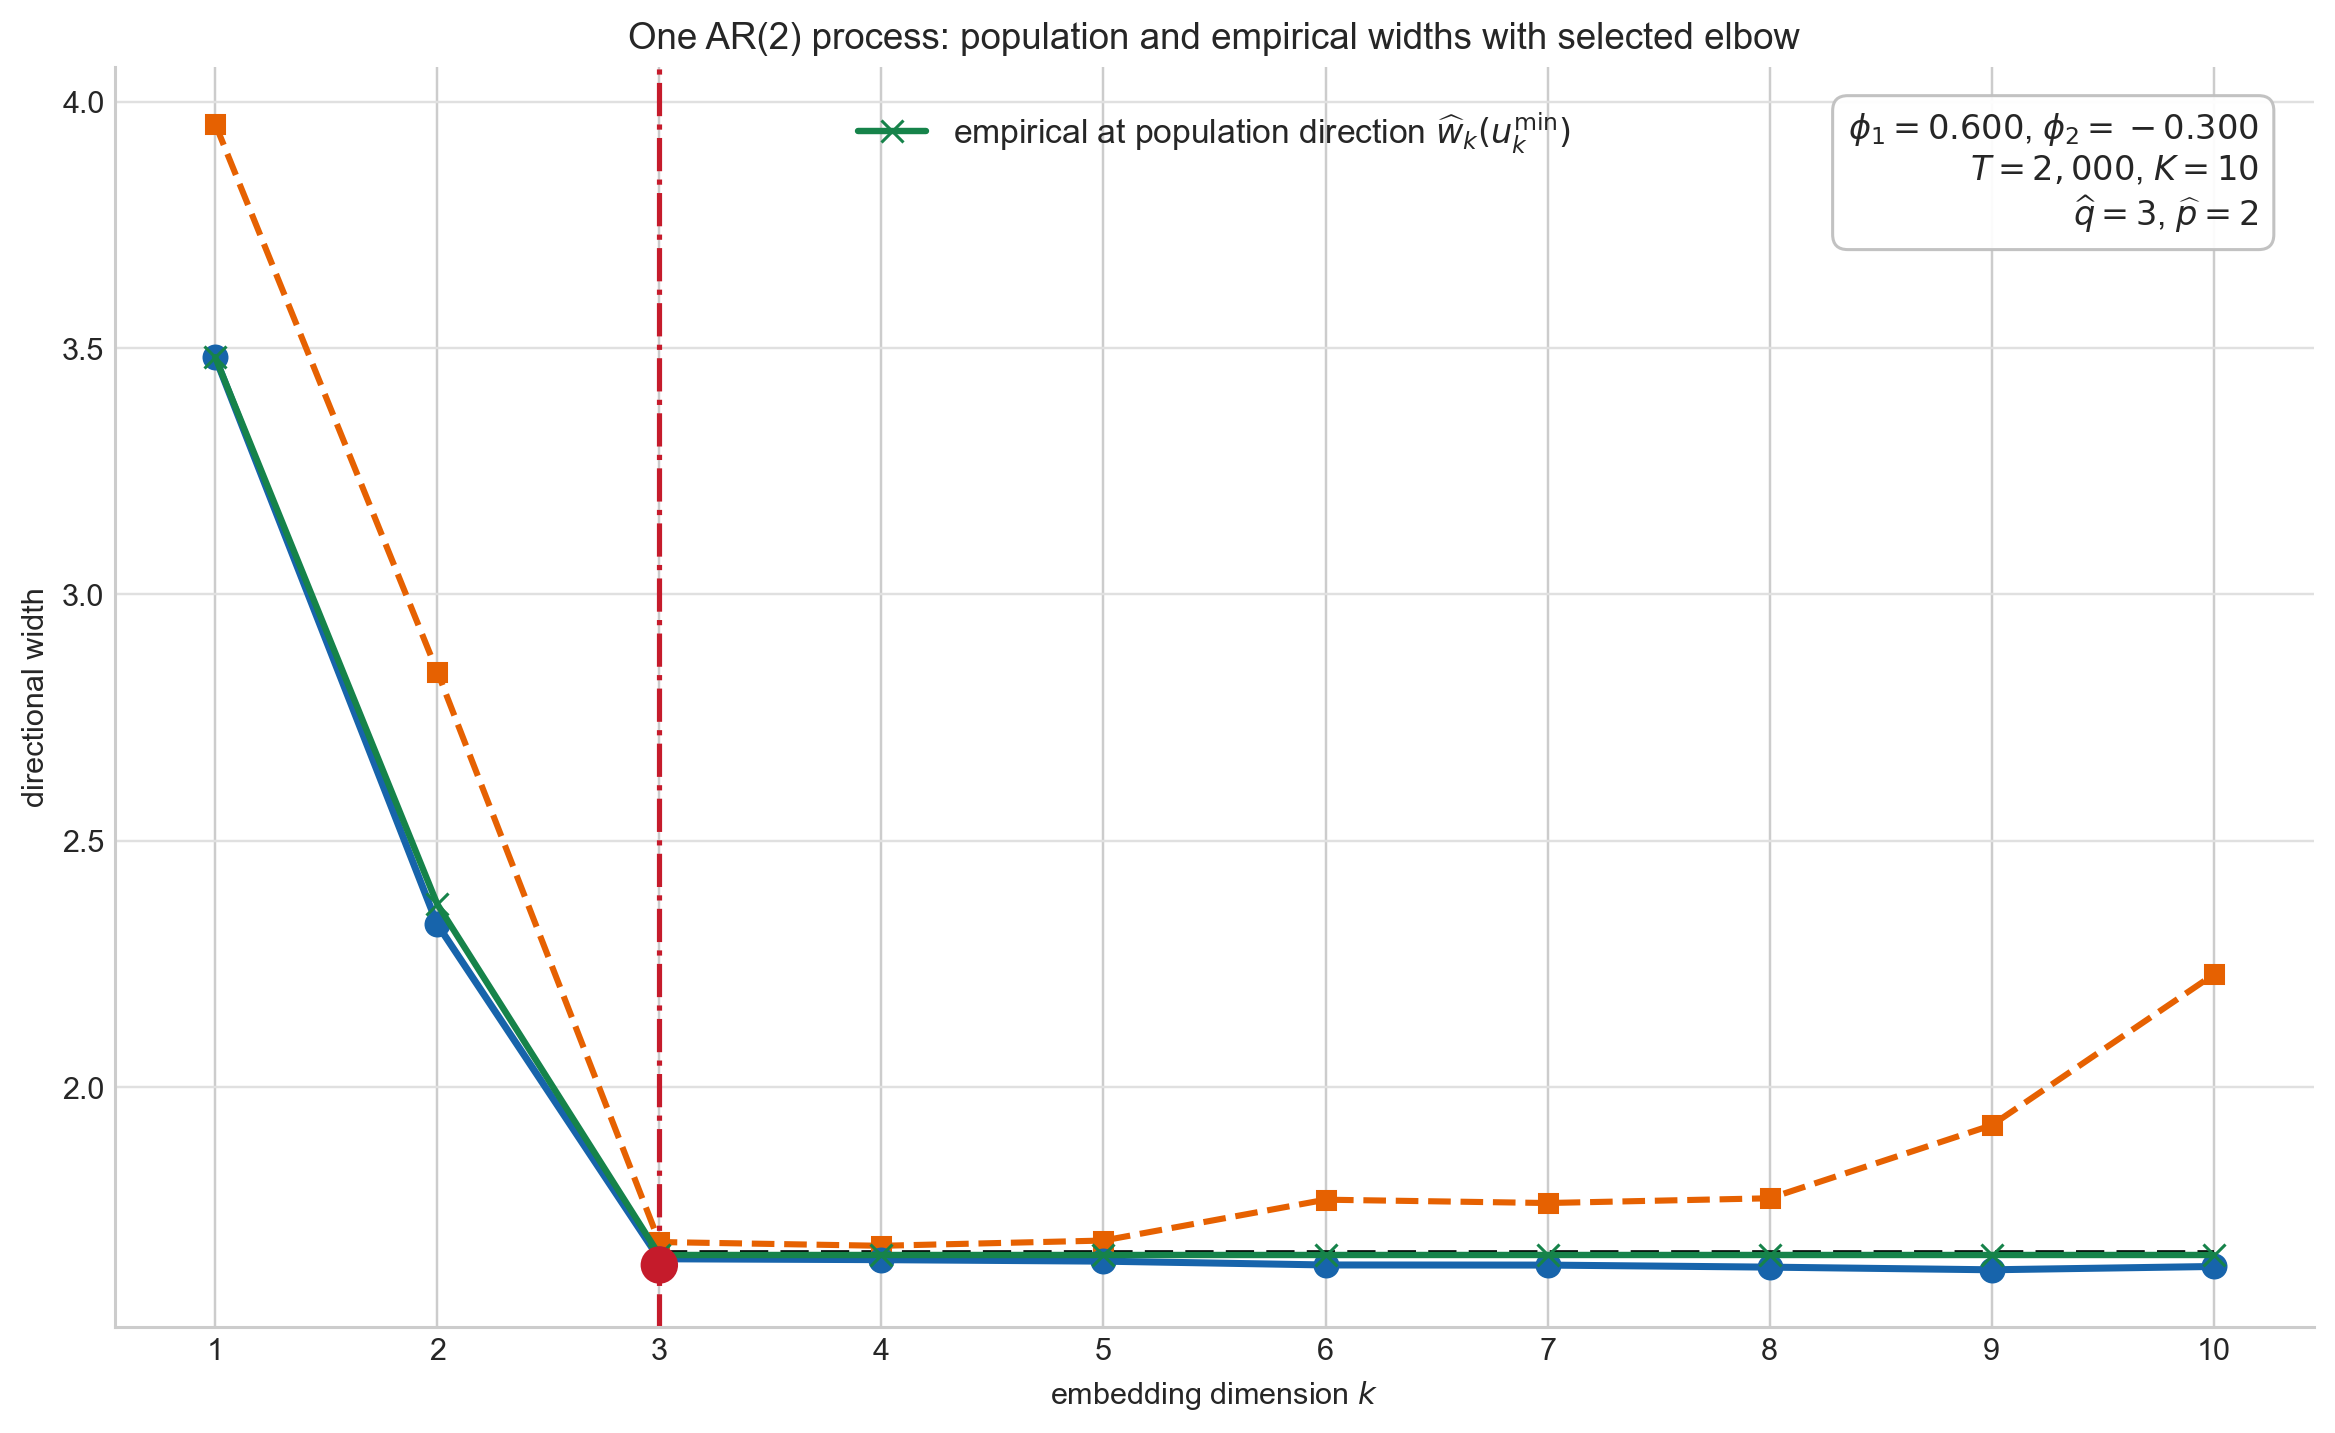

AR coefficients = [ 0.6 -0.3]
Population plateau m* = 1.660910
Selected q = 3; selected AR order p = 2; LAD score = 0.278122
Estimated coefficients from the empirical minimizing direction at k = 3:
  phi_1_hat = 0.605058
  phi_2_hat = -0.308672


In [8]:
single_ar2_seed = 20260814
single_ar2_replication = 1
single_ar2_T = 2_000
single_ar2_burnin = 1_000
single_ar2_k_values = np.arange(1, 11)
single_ar2_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar2_seed, single_ar2_replication, 0
]))
single_ar2_phi = np.array([0.6, -0.3])
single_ar2_series = simulate_uniform_ar(
    single_ar2_phi, single_ar2_T, single_ar2_burnin, 1.0,
    rng=single_ar2_generator,
)
_, single_ar2_widths, _, single_ar2_empirical_directions = (
    batched_geometric_width_curves(
        single_ar2_series,
        int(single_ar2_k_values.max()),
        seed=single_ar2_seed,
        replication=single_ar2_replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
        return_directions=True,
    )
)
single_ar2_selection = l_method_selector(
    single_ar2_widths, weighted=False, common_breakpoint=True,
    affine_affine=False, squared_loss=False,
)
single_ar2_q_hat = single_ar2_selection["plateau_onset"]
single_ar2_p_hat = single_ar2_selection["selected_order"]
single_ar2_estimated_phi = coefficients_from_minimizing_direction(
    single_ar2_empirical_directions[single_ar2_q_hat - 1]
)
single_ar2_population_width = 2.0 / np.linalg.norm(
    np.r_[1.0, -single_ar2_phi]
)
single_ar2_population_directions = []
single_ar2_empirical_at_population_min = []
single_ar2_population_at_empirical_min = []
for k, empirical_direction in zip(
    single_ar2_k_values, single_ar2_empirical_directions
):
    population_direction = population_minimizing_direction(single_ar2_phi, int(k))
    cloud_k = sliding_window_point_cloud(single_ar2_series, int(k))
    single_ar2_population_directions.append(population_direction)
    single_ar2_empirical_at_population_min.append(
        np.ptp(cloud_k @ population_direction)
    )
    single_ar2_population_at_empirical_min.append(
        theoretical_ar_width_in_direction(
            single_ar2_phi, empirical_direction, half_width=1.0
        )
    )
single_ar2_empirical_at_population_min = np.asarray(
    single_ar2_empirical_at_population_min
)
single_ar2_population_at_empirical_min = np.asarray(
    single_ar2_population_at_empirical_min
)

single_ar2_pipeline_results = pd.DataFrame({                                                        ### REPORTING
    "k": single_ar2_k_values,                                                                       ### REPORTING
    "empirical_width": single_ar2_widths,                                                           ### REPORTING
    "population_width": np.where(                                                                   ### REPORTING
        single_ar2_k_values >= 3, single_ar2_population_width, np.nan                               ### REPORTING
    ),                                                                                              ### REPORTING
    "empirical_at_population_min": (                                                                ### REPORTING
        single_ar2_empirical_at_population_min                                                      ### REPORTING
    ),                                                                                              ### REPORTING
    "population_at_empirical_min": (                                                                ### REPORTING
        single_ar2_population_at_empirical_min                                                      ### REPORTING
    ),                                                                                              ### REPORTING
    "selected_LAD_fit": single_ar2_selection["fitted_values"],                                      ### REPORTING
})                                                                                                  ### REPORTING

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)                              ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar2_k_values, single_ar2_widths, color="#1764ab",                                        ### PLOTTING
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,                                            ### PLOTTING
    label=r"empirical $\widehat m_k$",                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar2_k_values[2:],                                                                        ### PLOTTING
    np.full(len(single_ar2_k_values) - 2, single_ar2_population_width),                             ### PLOTTING
    color="black", linestyle="--", linewidth=2.5, zorder=2,                                         ### PLOTTING
    label=r"population $m_k=m^*$ for $k\geq3$",                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar2_k_values, single_ar2_population_at_empirical_min,                                    ### PLOTTING
    color="#e66101", marker="s", markersize=5.8,                                                    ### PLOTTING
    linestyle="--", linewidth=2.0, zorder=3,                                                        ### PLOTTING
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",                                 ### PLOTTING
)                                                                                                   ### PLOTTING
green_line, = axis.plot(                                                                            ### PLOTTING
    single_ar2_k_values, single_ar2_empirical_at_population_min,                                    ### PLOTTING
    color="#16834a", marker="x", markersize=7.5, linewidth=2.1, zorder=5,                           ### PLOTTING
    label=r"empirical at population direction $\widehat w_k(u_k^{\min})$",                          ### PLOTTING
)                                                                                                   ### PLOTTING
axis.legend(handles=[green_line], loc="upper center", bbox_to_anchor=(0.5, 0.99),                   ### PLOTTING
            frameon=False, fontsize=11)                                                             ### PLOTTING
axis.axvline(                                                                                       ### PLOTTING
    single_ar2_q_hat, color="#c51b2b", linestyle="-.",                                              ### PLOTTING
    linewidth=1.7, zorder=1,                                                                        ### PLOTTING
    label=rf"selected $\widehat q={single_ar2_q_hat}$ ($\widehat p={single_ar2_p_hat}$)",           ### PLOTTING
)                                                                                                   ### PLOTTING
axis.scatter(                                                                                       ### PLOTTING
    [single_ar2_q_hat], [single_ar2_selection["right_intercept"]],                                  ### PLOTTING
    marker="o", s=150, color="#c51b2b", edgecolor="none",                                           ### PLOTTING
    zorder=7,                                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING
axis.text(                                                                                          ### PLOTTING
    0.975, 0.965,                                                                                   ### PLOTTING
    rf"$\phi_1={single_ar2_phi[0]:.3f}$, "                                                          ### PLOTTING
    + rf"$\phi_2={single_ar2_phi[1]:.3f}$" + "\n"                                                   ### PLOTTING
    + rf"$T={single_ar2_T:,}$, $K={single_ar2_k_values[-1]}$" + "\n"                                ### PLOTTING
    + rf"$\widehat q={single_ar2_q_hat}$, $\widehat p={single_ar2_p_hat}$",                         ### PLOTTING
    transform=axis.transAxes, ha="right", va="top", fontsize=11,                                    ### PLOTTING
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",                                       ### PLOTTING
          "edgecolor": "0.75", "alpha": 0.94},                                                      ### PLOTTING
)                                                                                                   ### PLOTTING
axis.set(                                                                                           ### PLOTTING
    title="One AR(2) process: population and empirical widths with selected elbow",                 ### PLOTTING
    xlabel=r"embedding dimension $k$",                                                              ### PLOTTING
    ylabel=r"directional width",                                                                    ### PLOTTING
    xticks=single_ar2_k_values,                                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
axis.grid(axis="y", color="0.88", linewidth=0.8)                                                    ### PLOTTING
axis.spines[["top", "right"]].set_visible(False)                                                    ### PLOTTING
for extension in ("pdf", "png"):                                                                    ### PLOTTING
    fig.savefig(                                                                                    ### PLOTTING
        FIGURE_OUTPUT_DIR / f"AR2_experiment.{extension}",                                          ### PLOTTING
        dpi=220, bbox_inches="tight",                                                               ### PLOTTING
    )                                                                                               ### PLOTTING
plt.show()                                                                                          ### PLOTTING

print(f"AR coefficients = {single_ar2_phi}")                                                        ### REPORTING
print(f"Population plateau m* = {single_ar2_population_width:.6f}")                                 ### REPORTING
print(                                                                                              ### REPORTING
    f"Selected q = {single_ar2_q_hat}; "                                                            ### REPORTING
    f"selected AR order p = {single_ar2_p_hat}; "                                                   ### REPORTING
    f"LAD score = {single_ar2_selection['score']:.6f}"                                              ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    "Estimated coefficients from the empirical minimizing direction "                               ### REPORTING
    + f"at k = {single_ar2_q_hat}:"                                                                 ### REPORTING
)                                                                                                   ### REPORTING
for coefficient_index, coefficient in enumerate(single_ar2_estimated_phi, start=1):                 ### REPORTING
    print(f"  phi_{coefficient_index}_hat = {coefficient:.6f}")                                     ### REPORTING


## One complete AR(3) pipeline and its selected elbow

This repeats the preceding display for one fixed AR(3) process, with the same $T=2{,}000$, $K=10$, three optimization starts, 500 projected-subgradient iterations, and the unweighted shared-point affine-plus-constant LAD selector. The population minimum is displayed only for $k\ge p+1=4$, where $m_k=m^*=2/\lVert(1,-\phi_1,-\phi_2,-\phi_3)\rVert_2$. The green curve evaluates the empirical width in a population-minimizing direction; for $k<4$, that direction comes from a finite-history support-zonotope approximation. The orange curve evaluates the population support width in the empirically minimized direction.

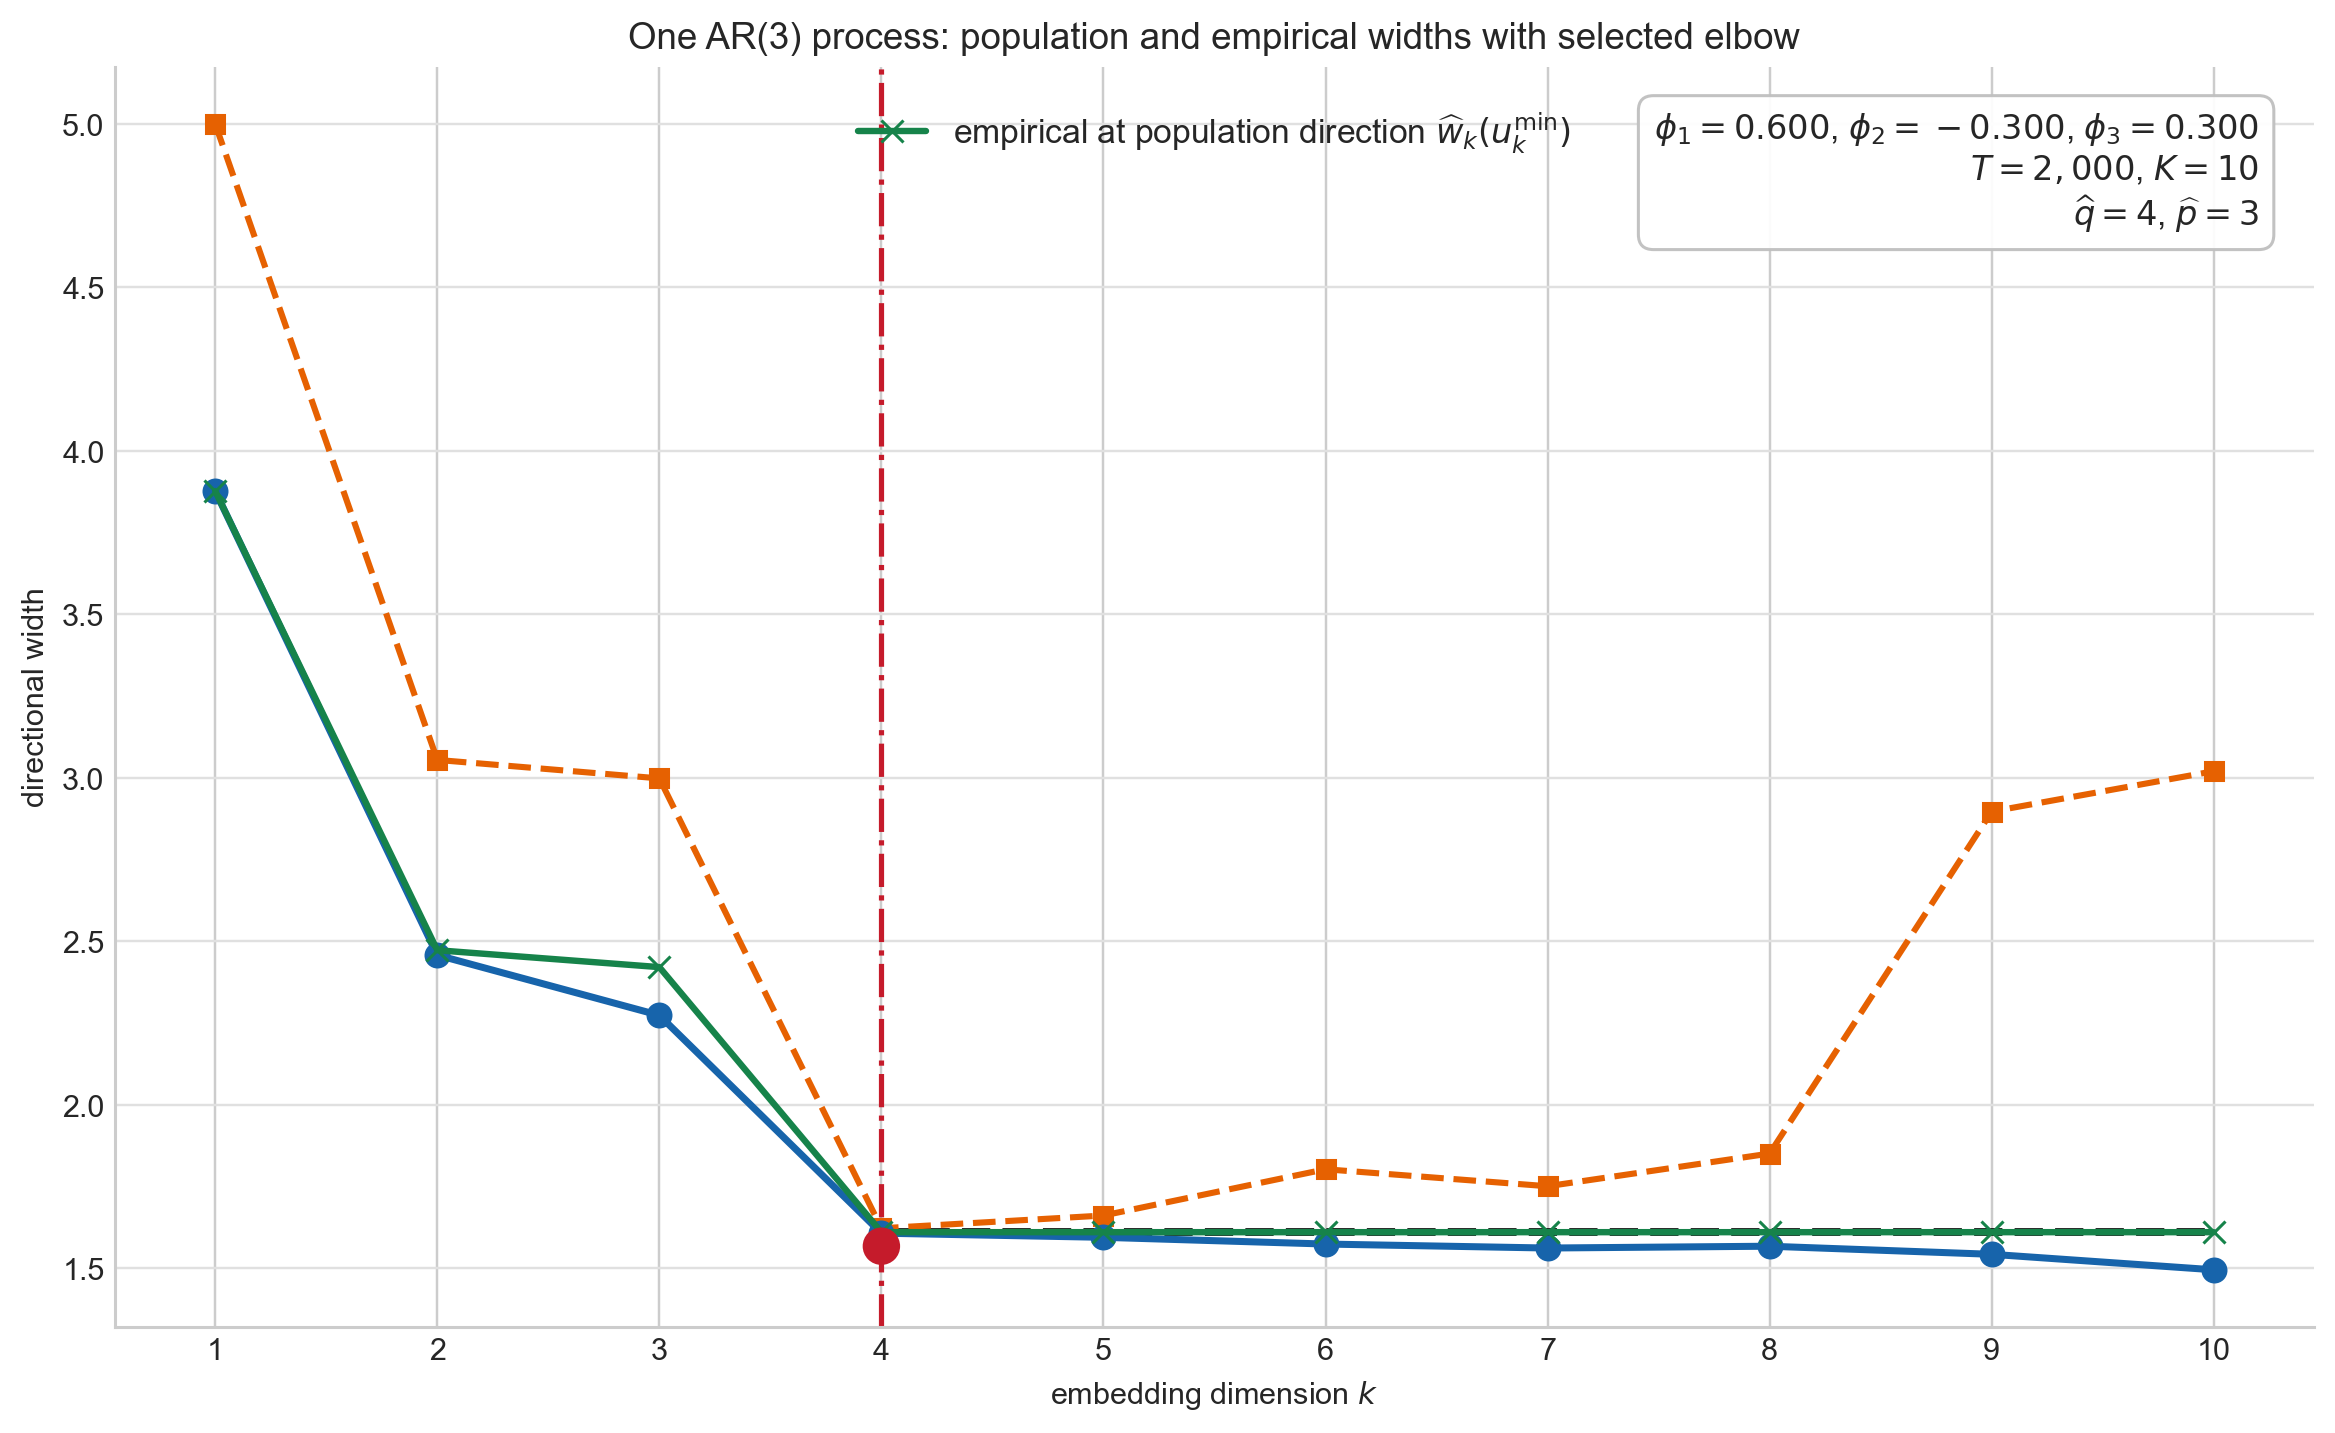

AR coefficients = [ 0.6 -0.3  0.3]
Population plateau m* = 1.611646
Selected q = 4; selected AR order p = 3; LAD score = 0.889059
Estimated coefficients from the empirical minimizing direction at k = 4:
  phi_1_hat = 0.602940
  phi_2_hat = -0.302585
  phi_3_hat = 0.302667


In [9]:
single_ar3_seed = 20260816
single_ar3_replication = 9
single_ar3_T = 2_000
single_ar3_burnin = 1_000
single_ar3_k_values = np.arange(1, 11)
single_ar3_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar3_seed, single_ar3_replication, 0
]))
single_ar3_phi = np.array([0.6, -0.3, 0.3])
single_ar3_series = simulate_uniform_ar(
    single_ar3_phi, single_ar3_T, single_ar3_burnin, 1.0,
    rng=single_ar3_generator,
)
_, single_ar3_widths, _, single_ar3_empirical_directions = (
    batched_geometric_width_curves(
        single_ar3_series,
        int(single_ar3_k_values.max()),
        seed=single_ar3_seed,
        replication=single_ar3_replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
        return_directions=True,
    )
)
single_ar3_selection = l_method_selector(
    single_ar3_widths, weighted=False, common_breakpoint=True,
    affine_affine=False, squared_loss=False,
)
single_ar3_q_hat = single_ar3_selection["plateau_onset"]
single_ar3_p_hat = single_ar3_selection["selected_order"]
single_ar3_estimated_phi = coefficients_from_minimizing_direction(
    single_ar3_empirical_directions[single_ar3_q_hat - 1]
)
single_ar3_population_width = 2.0 / np.linalg.norm(
    np.r_[1.0, -single_ar3_phi]
)
single_ar3_population_directions = []
single_ar3_empirical_at_population_min = []
single_ar3_population_at_empirical_min = []
for k, empirical_direction in zip(
    single_ar3_k_values, single_ar3_empirical_directions
):
    population_direction = population_minimizing_direction(single_ar3_phi, int(k))
    cloud_k = sliding_window_point_cloud(single_ar3_series, int(k))
    single_ar3_population_directions.append(population_direction)
    single_ar3_empirical_at_population_min.append(
        np.ptp(cloud_k @ population_direction)
    )
    single_ar3_population_at_empirical_min.append(
        theoretical_ar_width_in_direction(
            single_ar3_phi, empirical_direction, half_width=1.0
        )
    )
single_ar3_empirical_at_population_min = np.asarray(
    single_ar3_empirical_at_population_min
)
single_ar3_population_at_empirical_min = np.asarray(
    single_ar3_population_at_empirical_min
)

single_ar3_pipeline_results = pd.DataFrame({                                                        ### REPORTING
    "k": single_ar3_k_values,                                                                       ### REPORTING
    "empirical_width": single_ar3_widths,                                                           ### REPORTING
    "population_width": np.where(                                                                   ### REPORTING
        single_ar3_k_values >= 4, single_ar3_population_width, np.nan                               ### REPORTING
    ),                                                                                              ### REPORTING
    "empirical_at_population_min": (                                                                ### REPORTING
        single_ar3_empirical_at_population_min                                                      ### REPORTING
    ),                                                                                              ### REPORTING
    "population_at_empirical_min": (                                                                ### REPORTING
        single_ar3_population_at_empirical_min                                                      ### REPORTING
    ),                                                                                              ### REPORTING
    "selected_LAD_fit": single_ar3_selection["fitted_values"],                                      ### REPORTING
})                                                                                                  ### REPORTING

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)                              ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar3_k_values, single_ar3_widths, color="#1764ab",                                        ### PLOTTING
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,                                            ### PLOTTING
    label=r"empirical $\widehat m_k$",                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar3_k_values[3:],                                                                        ### PLOTTING
    np.full(len(single_ar3_k_values) - 3, single_ar3_population_width),                             ### PLOTTING
    color="black", linestyle="--", linewidth=2.5, zorder=2,                                         ### PLOTTING
    label=r"population $m_k=m^*$ for $k\geq4$",                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar3_k_values, single_ar3_population_at_empirical_min,                                    ### PLOTTING
    color="#e66101", marker="s", markersize=5.8,                                                    ### PLOTTING
    linestyle="--", linewidth=2.0, zorder=3,                                                        ### PLOTTING
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",                                 ### PLOTTING
)                                                                                                   ### PLOTTING
green_line, = axis.plot(                                                                            ### PLOTTING
    single_ar3_k_values, single_ar3_empirical_at_population_min,                                    ### PLOTTING
    color="#16834a", marker="x", markersize=7.5, linewidth=2.1, zorder=5,                           ### PLOTTING
    label=r"empirical at population direction $\widehat w_k(u_k^{\min})$",                          ### PLOTTING
)                                                                                                   ### PLOTTING
axis.legend(handles=[green_line], loc="upper center", bbox_to_anchor=(0.5, 0.99),                   ### PLOTTING
            frameon=False, fontsize=11)                                                             ### PLOTTING
axis.axvline(                                                                                       ### PLOTTING
    single_ar3_q_hat, color="#c51b2b", linestyle="-.",                                              ### PLOTTING
    linewidth=1.7, zorder=1,                                                                        ### PLOTTING
    label=rf"selected $\widehat q={single_ar3_q_hat}$ ($\widehat p={single_ar3_p_hat}$)",           ### PLOTTING
)                                                                                                   ### PLOTTING
axis.scatter(                                                                                       ### PLOTTING
    [single_ar3_q_hat], [single_ar3_selection["right_intercept"]],                                  ### PLOTTING
    marker="o", s=150, color="#c51b2b", edgecolor="none",                                           ### PLOTTING
    zorder=7,                                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING
axis.text(                                                                                          ### PLOTTING
    0.975, 0.965,                                                                                   ### PLOTTING
    rf"$\phi_1={single_ar3_phi[0]:.3f}$, "                                                          ### PLOTTING
    + rf"$\phi_2={single_ar3_phi[1]:.3f}$, "                                                        ### PLOTTING
    + rf"$\phi_3={single_ar3_phi[2]:.3f}$" + "\n"                                                   ### PLOTTING
    + rf"$T={single_ar3_T:,}$, $K={single_ar3_k_values[-1]}$" + "\n"                                ### PLOTTING
    + rf"$\widehat q={single_ar3_q_hat}$, $\widehat p={single_ar3_p_hat}$",                         ### PLOTTING
    transform=axis.transAxes, ha="right", va="top", fontsize=11,                                    ### PLOTTING
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",                                       ### PLOTTING
          "edgecolor": "0.75", "alpha": 0.94},                                                      ### PLOTTING
)                                                                                                   ### PLOTTING
axis.set(                                                                                           ### PLOTTING
    title="One AR(3) process: population and empirical widths with selected elbow",                 ### PLOTTING
    xlabel=r"embedding dimension $k$",                                                              ### PLOTTING
    ylabel=r"directional width",                                                                    ### PLOTTING
    xticks=single_ar3_k_values,                                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
axis.grid(axis="y", color="0.88", linewidth=0.8)                                                    ### PLOTTING
axis.spines[["top", "right"]].set_visible(False)                                                    ### PLOTTING
for extension in ("pdf", "png"):                                                                    ### PLOTTING
    fig.savefig(                                                                                    ### PLOTTING
        FIGURE_OUTPUT_DIR / f"AR3_experiment.{extension}",                                          ### PLOTTING
        dpi=220, bbox_inches="tight",                                                               ### PLOTTING
    )                                                                                               ### PLOTTING
plt.show()                                                                                          ### PLOTTING

print(f"AR coefficients = {single_ar3_phi}")                                                        ### REPORTING
print(f"Population plateau m* = {single_ar3_population_width:.6f}")                                 ### REPORTING
print(                                                                                              ### REPORTING
    f"Selected q = {single_ar3_q_hat}; "                                                            ### REPORTING
    f"selected AR order p = {single_ar3_p_hat}; "                                                   ### REPORTING
    f"LAD score = {single_ar3_selection['score']:.6f}"                                              ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    "Estimated coefficients from the empirical minimizing direction "                               ### REPORTING
    + f"at k = {single_ar3_q_hat}:"                                                                 ### REPORTING
)                                                                                                   ### REPORTING
for coefficient_index, coefficient in enumerate(single_ar3_estimated_phi, start=1):                 ### REPORTING
    print(f"  phi_{coefficient_index}_hat = {coefficient:.6f}")                                     ### REPORTING
